# Лабораторная работа № 2. Исследование задачи принятия решений на марковском процессе

**Выполнил:** Лешкевич Сергей, группа 09-535

**Задача.** Среда «Замёрзшее озеро» (FrozenLake): агент ходит по сетке из клеток и должен дойти от старта S до цели G,
не провалившись в полынью H. Лёд скользкий: агент идёт не всегда туда, куда собирался. За достижение цели даётся
награда 1, в остальных случаях 0. Это марковский процесс принятия решений (MDP): следующее состояние зависит только
от текущего состояния и действия, а вероятности переходов среды известны заранее (`env.P`).

Раз модель среды известна, оптимальную стратегию можно не «нащупывать» пробами, а **вычислить** методами
динамического программирования:
* **итерация по ценности** (value iteration) — уточняем ценности состояний, пока они не перестанут меняться,
  потом берём жадную стратегию;
* **итерация по стратегиям** (policy iteration) — по очереди оцениваем текущую стратегию и улучшаем её,
  пока она не перестанет меняться.

**План исследования.**
1. Разобрать среду (как в учебном блокноте) и проверить случайную стратегию.
2. Реализовать оба алгоритма, получить оптимальную стратегию на картах 4×4 и 8×8, проверить её в среде.
3. Исследовать влияние параметров алгоритмов: коэффициента дисконтирования γ, порога остановки θ,
   числа проходов оценки стратегии.
4. Исследовать влияние параметров среды: размера карты, вероятности проскальзывания, плотности полыней,
   наград за шаг и за падение в полынью.

**Чем меряем качество стратегии.**
* **Вероятность дойти до цели** — считается точно по модели среды (без ограничения на число шагов).
* **Доля успешных эпизодов в симуляции** — стратегия запускается в самой среде `gymnasium` много раз.
  Эпизод обрывается через 100 шагов на карте 4×4 и через 200 шагов на 8×8, как в стандартной среде.
* **Среднее число шагов** в эпизоде.

In [1]:
import time  # замер времени работы алгоритмов

# numpy - вся математика, matplotlib - графики
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# gymnasium - современная версия библиотеки gym из учебного блокнота, среда та же самая
import gymnasium as gym
from gymnasium.envs.toy_text.frozen_lake import generate_random_map  # генератор случайных карт

# Общий вид всех графиков: светлая сетка, без верхней и правой рамки, легенда без рамки
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.grid': True,
    'grid.color': '#e4e3df',
    'grid.linewidth': 0.8,
    'axes.edgecolor': '#b5b4ad',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'lines.linewidth': 1.6,
    'legend.frameon': False,
    'font.size': 9,
})

# Цвета по порядку - одинаковые во всех графиках
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6']

## 1. Среда «Замёрзшее озеро»

Карта 4×4 по умолчанию. Клетки: **S** — старт, **F** — лёд (можно ходить), **H** — полынья (эпизод заканчивается, награда 0),
**G** — цель (эпизод заканчивается, награда 1). Состояние — номер клетки от 0 до 15 (слева направо, сверху вниз).
Действия: 0 — влево, 1 — вниз, 2 — вправо, 3 — вверх.

Лёд скользкий: с вероятностью 1/3 агент идёт куда хотел, а с вероятностью 1/3 — в каждую из двух перпендикулярных
сторон. Назад его не сносит никогда.

In [2]:
def make_env(map_name='4x4', desc=None, slippery=True, success_rate=1 / 3, reward_schedule=(1, 0, 0)):
    # Создаёт среду FrozenLake с нужными настройками.
    # desc - своя карта (список строк); если не задана, берётся стандартная map_name.
    # success_rate - с какой вероятностью агент идёт куда хотел (только для скользкого льда).
    # reward_schedule - награды (за цель, за полынью, за обычный шаг по льду).
    size = len(desc) if desc else int(map_name[0])
    return gym.make(
        'FrozenLake-v1', desc=desc, map_name=map_name, is_slippery=slippery,
        success_rate=success_rate, reward_schedule=reward_schedule,
        max_episode_steps=100 if size <= 4 else 200,  # обрыв эпизода, как у стандартных сред 4x4 и 8x8
    )


env = make_env()
n_state = env.observation_space.n  # число состояний = число клеток
n_action = env.action_space.n  # число действий
print('Состояний:', n_state, ' действий:', n_action)
print(env.unwrapped.desc.astype(str))  # сама карта

# Один шаг, как в учебном блокноте: из старта пробуем пойти вниз (действие 1)
state, info = env.reset(seed=0)
new_state, reward, terminated, truncated, info = env.step(1)
print('Шаг вниз из старта: новое состояние', new_state, ' награда', reward, ' конец', terminated, info)

# Модель среды: env.P[состояние][действие] = список (вероятность, следующее состояние, награда, конец ли)
print('\nПереходы из клетки 6:')
for action, transitions in env.unwrapped.P[6].items():
    print(f'  действие {action}:', [(round(p, 3), s, r, done) for p, s, r, done in transitions])

Состояний: 16  действий: 4
[['S' 'F' 'F' 'F']
 ['F' 'H' 'F' 'H']
 ['F' 'F' 'F' 'H']
 ['H' 'F' 'F' 'G']]
Шаг вниз из старта: новое состояние 0  награда 0  конец False {'prob': 0.33333333333333337}

Переходы из клетки 6:
  действие 0: [(0.333, 2, 0, False), (0.333, 5, 0, True), (0.333, 10, 0, False)]
  действие 1: [(0.333, 5, 0, True), (0.333, 10, 0, False), (0.333, 7, 0, True)]
  действие 2: [(0.333, 10, 0, False), (0.333, 7, 0, True), (0.333, 2, 0, False)]
  действие 3: [(0.333, 7, 0, True), (0.333, 2, 0, False), (0.333, 5, 0, True)]


### Случайная стратегия

Стратегия — это таблица «в какой клетке какое действие делать». Как в учебном блокноте, запускаем эпизоды
с каждый раз новой случайной стратегией и смотрим среднюю награду, то есть долю успешных эпизодов.

In [3]:
def run_episode(env, policy):
    # Один эпизод: ходим по стратегии, пока не упадём, не дойдём или не кончится лимит шагов.
    # Возвращает полученную награду и сколько шагов сделали.
    state, _ = env.reset()
    total_reward, steps = 0.0, 0
    while True:
        state, reward, terminated, truncated, _ = env.step(int(policy[state]))
        total_reward += reward
        steps += 1
        if terminated or truncated:  # terminated - упали или дошли, truncated - кончился лимит шагов
            return total_reward, steps


def test_policy(env, policy, n_episode=10000, seed=0):
    # Запускает стратегию n_episode раз и возвращает долю успехов и среднее число шагов.
    # Награда за цель 1, иначе 0, поэтому средняя награда = доля успешных эпизодов.
    env.reset(seed=seed)  # фиксируем случайность, чтобы результат повторялся
    results = np.array([run_episode(env, policy) for _ in range(n_episode)])
    return results[:, 0].mean(), results[:, 1].mean()


rng = np.random.default_rng(0)
env.reset(seed=0)
random_rewards = [run_episode(env, rng.integers(0, n_action, n_state))[0] for _ in range(10000)]
print(f'Случайная стратегия (новая на каждый эпизод): доля успехов {np.mean(random_rewards):.4f}')

Случайная стратегия (новая на каждый эпизод): доля успехов 0.0158


## 2. Модель среды в виде массивов

Для вычислений удобно переложить `env.P` в два массива:
* `T[s, a, s']` — вероятность из состояния s при действии a попасть в s' **и продолжить игру**;
* `R[s, a]` — ожидаемая награда за шаг из s при действии a.

Переходы, после которых эпизод кончается (в полынью или в цель), в `T` не попадают: после конца эпизода будущих наград
нет. Их награда учтена в `R`. Тогда уравнение Беллмана записывается одной строкой:

$$Q(s,a) = R(s,a) + \gamma \sum_{s'} T(s,a,s')\, V(s')$$

In [4]:
def get_model(env):
    # Перекладывает модель среды env.P в массивы T (вероятности переходов) и R (ожидаемые награды).
    P = env.unwrapped.P
    n_s, n_a = len(P), len(P[0])
    T = np.zeros((n_s, n_a, n_s))
    R = np.zeros((n_s, n_a))
    for s, actions in P.items():
        for a, transitions in actions.items():
            for prob, s_next, reward, done in transitions:
                R[s, a] += prob * reward  # награда в среднем = сумма (вероятность * награда)
                if not done:  # если эпизод не кончился, дальше будет ценность следующего состояния
                    T[s, a, s_next] += prob
    return T, R


def greedy(Q):
    # Жадная стратегия: в каждом состоянии действие с наибольшим Q.
    # Значения округляем, чтобы почти равные из-за погрешности числа считались равными;
    # из равных argmax берёт первое, поэтому результат не зависит от мелкого шума.
    return np.argmax(np.round(Q, 10), axis=1)


T, R = get_model(env)
print('T:', T.shape, ' R:', R.shape)
print('Из клетки 6 действием «вниз» продолжаем игру с вероятностью', T[6, 1].sum().round(3),
      '- в остальных случаях падаем в полынью')

T: (16, 4, 16)  R: (16, 4)
Из клетки 6 действием «вниз» продолжаем игру с вероятностью 0.333 - в остальных случаях падаем в полынью


## 3. Итерация по ценности

Начинаем с V = 0 и много раз применяем уравнение оптимальности Беллмана ко всем состояниям сразу:

$$V_{k+1}(s) = \max_a \left[ R(s,a) + \gamma \sum_{s'} T(s,a,s')\, V_k(s') \right]$$

Останавливаемся, когда за проход ни одна ценность не изменилась больше чем на θ. Оптимальная стратегия —
жадная по полученным ценностям.

In [5]:
def value_iteration(T, R, gamma=0.99, theta=1e-10, max_iter=1_000_000):
    # Итерация по ценности. Возвращает ценности V, стратегию, число итераций
    # и историю: насколько менялись ценности и чему была равна ценность старта на каждой итерации.
    V = np.zeros(T.shape[0])  # начинаем с нулевых ценностей
    deltas, v_start = [], []
    for iteration in range(1, max_iter + 1):
        Q = R + gamma * T @ V  # ценности всех пар (состояние, действие) по текущим V
        V_new = Q.max(axis=1)  # в каждом состоянии берём лучшее действие
        delta = np.abs(V_new - V).max()  # самое большое изменение за итерацию
        V = V_new
        deltas.append(delta)
        v_start.append(V[0])  # старт всегда в клетке 0
        if delta < theta:  # ценности почти перестали меняться - готово
            break
    policy = greedy(R + gamma * T @ V)  # стратегия: в каждом состоянии лучшее действие
    return dict(V=V, policy=policy, iterations=iteration,
                deltas=np.array(deltas), v_start=np.array(v_start))

## 4. Итерация по стратегиям

Начинаем с произвольной стратегии (везде «влево») и повторяем два шага, пока стратегия не перестанет меняться:
1. **Оценка стратегии:** находим ценности V<sup>π</sup> текущей стратегии, тоже итерациями Беллмана, но без max —
   действие задано стратегией:

$$V(s) \leftarrow R(s,\pi(s)) + \gamma \sum_{s'} T(s,\pi(s),s')\, V(s')$$

2. **Улучшение стратегии:** в каждом состоянии выбираем действие, жадное по V<sup>π</sup>.

Оценку каждой новой стратегии начинаем с ценностей предыдущей — так нужно меньше проходов.
Параметр `eval_sweeps` ограничивает число проходов оценки. Если его задать, получится
**модифицированная итерация по стратегиям**: при `eval_sweeps = 1` она почти совпадает с итерацией по ценности.

In [6]:
def policy_evaluation(T, R, policy, gamma, theta=1e-10, V=None, max_sweeps=None):
    # Оценка стратегии: ценности состояний, если всегда действовать по policy.
    # V - с каких ценностей начать (по умолчанию с нулей), max_sweeps - ограничение числа проходов.
    # Возвращает ценности, число проходов и последнее изменение ценностей.
    idx = np.arange(len(policy))
    T_pi = T[idx, policy]  # вероятности переходов при действиях из стратегии, матрица S x S
    R_pi = R[idx, policy]  # награды при этих действиях
    V = np.zeros(len(policy)) if V is None else V.copy()
    sweeps = 0
    while True:
        V_new = R_pi + gamma * T_pi @ V
        delta = np.abs(V_new - V).max()
        V = V_new
        sweeps += 1
        if delta < theta or sweeps == max_sweeps or sweeps >= 1_000_000:
            return V, sweeps, delta


def policy_iteration(T, R, gamma=0.99, theta=1e-10, eval_sweeps=None):
    # Итерация по стратегиям. eval_sweeps - сколько проходов оценки делать на каждом шаге
    # (None - до сходимости, это классический вариант).
    n_s = T.shape[0]
    idx = np.arange(n_s)
    policy = np.zeros(n_s, dtype=int)  # начальная стратегия: везде «влево»
    V = np.zeros(n_s)
    history = []  # на каждом шаге: сколько проходов оценки, сколько действий поменялось, ценность старта
    while True:
        V, sweeps, delta = policy_evaluation(T, R, policy, gamma, theta, V, eval_sweeps)
        Q = R + gamma * T @ V
        new_policy = greedy(Q)
        # Действие меняем, только если новое действительно лучше. Иначе стратегия может
        # бесконечно прыгать между равноценными действиями и никогда не остановиться.
        keep = Q[idx, policy] >= Q[idx, new_policy] - 1e-12
        new_policy = np.where(keep, policy, new_policy)
        changed = int((new_policy != policy).sum())
        history.append((sweeps, changed, V[0]))
        policy = new_policy
        # стоп: стратегия не меняется и ценности досчитаны до точности theta
        if changed == 0 and delta < theta:
            break
    history = np.array(history)
    return dict(V=V, policy=policy, improvements=len(history),
                sweeps=int(history[:, 0].sum()), history=history)

### Точная вероятность дойти до цели

Если взять γ = 1 и награду 1 только за цель, то ценность старта при стратегии π — это ровно вероятность
когда-нибудь дойти до цели. Поэтому качество любой стратегии можно посчитать точно, той же оценкой стратегии.
Считаем всегда на стандартных наградах, даже если стратегию получали с другими наградами.

In [7]:
def desc_of(env):
    # Карта среды в виде списка строк, например ['SFFF', 'FHFH', ...]
    return [''.join(row) for row in env.unwrapped.desc.astype(str)]


def success_probability(env, policy):
    # Точная вероятность дойти от старта до цели, если действовать по policy (без лимита шагов).
    # Переходы берём из самой среды, а награду ставим «стандартную»: 1 за попадание в цель, остальное 0.
    T, _ = get_model(env)
    goal = ''.join(desc_of(env)).index('G')  # номер клетки цели
    R_goal = np.zeros(T.shape[:2])
    for s, actions in env.unwrapped.P.items():
        for a, transitions in actions.items():
            R_goal[s, a] = sum(prob for prob, s_next, _, _ in transitions if s_next == goal and s != goal)
    V, _, _ = policy_evaluation(T, R_goal, policy, gamma=1.0, theta=1e-12)
    return V[0]

### Рисование стратегии на карте

Цвет клетки — ценность V(s): чем темнее синий, тем ценнее состояние. Стрелка — действие стратегии в этой клетке.
Полыньи — тёмно-серые, цель — жёлтая.

In [8]:
ARROWS = '←↓→↑'  # значки действий 0, 1, 2, 3


def draw_policy(ax, env, V, policy, title=None, values=True):
    desc = env.unwrapped.desc.astype(str)
    n_rows, n_cols = desc.shape
    ax.imshow(V.reshape(desc.shape), cmap='Blues', vmin=0, vmax=max(V.max(), 1e-9))
    for i in range(n_rows):
        for j in range(n_cols):
            s = i * n_cols + j  # номер состояния
            cell = desc[i, j]
            if cell == 'H':
                ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, color='#3d3d3a'))
                ax.text(j, i, 'H', ha='center', va='center', color='white', fontsize=8)
            elif cell == 'G':
                ax.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, color='#eda100'))
                ax.text(j, i, 'G', ha='center', va='center', color='white', fontsize=9, fontweight='bold')
            else:
                # на тёмных клетках текст белый, на светлых - тёмный
                dark = V[s] > 0.55 * V.max()
                color = 'white' if dark else '#1f1f1d'
                big = n_rows <= 8
                ax.text(j, i - (0.12 if values and big else 0), ARROWS[policy[s]], ha='center', va='center',
                        color=color, fontsize=13 if big else 7)
                if values and big:
                    ax.text(j, i + 0.28, f'{V[s]:.2f}', ha='center', va='center', color=color, fontsize=6)
                if cell == 'S':
                    ax.text(j - 0.42, i - 0.42, 'S', ha='left', va='top', color=color,
                            fontsize=6, fontweight='bold')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    if title:
        ax.set_title(title, loc='left', fontsize=9.5)

## 5. Оптимальная стратегия на картах 4×4 и 8×8

Запускаем оба алгоритма с γ = 0.99 и θ = 10⁻¹⁰.

Карта 4x4:
  итерация по ценности:    571 итераций,   10.4 мс, V(старт) = 0.5420
  итерация по стратегиям:    7 улучшений, 1762 проходов оценки,   15.1 мс, V(старт) = 0.5420
  стратегии совпадают в 16 из 16 клеток, max |V_VI - V_PI| = 1.4e-11
Карта 8x8:
  итерация по ценности:    662 итераций,    9.5 мс, V(старт) = 0.4146
  итерация по стратегиям:   11 улучшений, 3861 проходов оценки,   18.3 мс, V(старт) = 0.4146
  стратегии совпадают в 64 из 64 клеток, max |V_VI - V_PI| = 1.8e-10


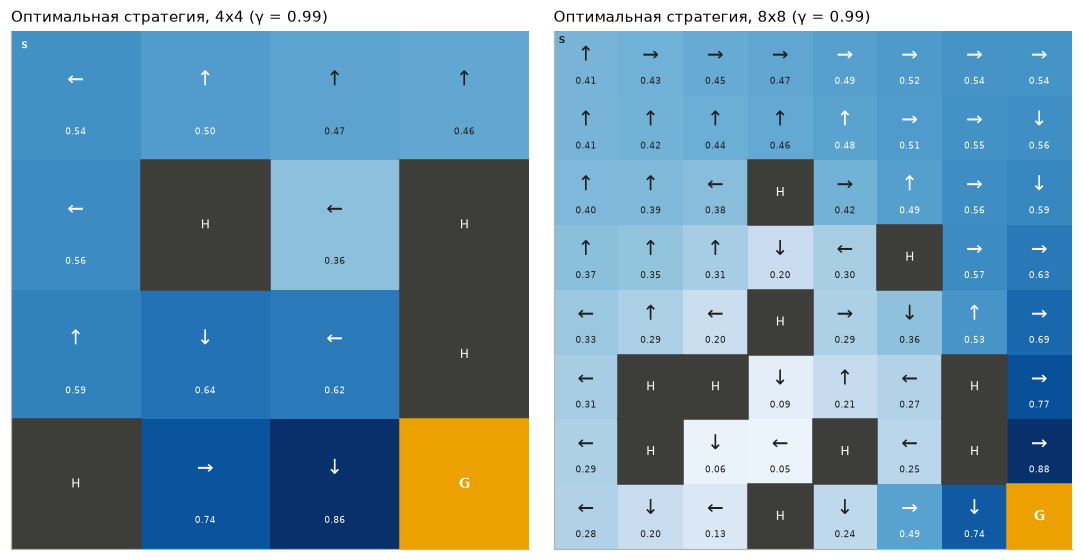

In [9]:
GAMMA, THETA = 0.99, 1e-10
envs = {'4x4': make_env('4x4'), '8x8': make_env('8x8')}
solutions = {}
for name, e in envs.items():
    T, R = get_model(e)
    t0 = time.perf_counter()
    vi = value_iteration(T, R, GAMMA, THETA)
    vi['time'] = time.perf_counter() - t0
    t0 = time.perf_counter()
    pi = policy_iteration(T, R, GAMMA, THETA)
    pi['time'] = time.perf_counter() - t0
    solutions[name] = (vi, pi)
    same = (vi['policy'] == pi['policy']).sum()
    print(f"Карта {name}:")
    print(f"  итерация по ценности:   {vi['iterations']:4d} итераций, {1000 * vi['time']:6.1f} мс, "
          f"V(старт) = {vi['V'][0]:.4f}")
    print(f"  итерация по стратегиям: {pi['improvements']:4d} улучшений, {pi['sweeps']} проходов оценки, "
          f"{1000 * pi['time']:6.1f} мс, V(старт) = {pi['V'][0]:.4f}")
    print(f"  стратегии совпадают в {same} из {len(vi['policy'])} клеток, "
          f"max |V_VI - V_PI| = {np.abs(vi['V'] - pi['V']).max():.1e}")

fig, axes = plt.subplots(1, 2, figsize=(10, 5), gridspec_kw={'width_ratios': [1, 1]})
for ax, name in zip(axes, envs):
    vi, _ = solutions[name]
    draw_policy(ax, envs[name], vi['V'], vi['policy'], f'Оптимальная стратегия, {name} (γ = {GAMMA})')
plt.tight_layout()
plt.show()

**Наблюдения.**

* Оба алгоритма нашли **одну и ту же стратегию** во всех клетках, ценности совпали до 10⁻¹⁰. Так и должно быть:
  оба метода сходятся к единственному решению уравнения оптимальности Беллмана.
* Итерация по ценности сделала 571 итерацию (4×4) и 662 (8×8). Итерация по стратегиям — всего 7 и 11 шагов улучшения,
  но внутри них 1762 и 3861 проход оценки. По времени на таких маленьких картах оба метода укладываются в 5–20 мс,
  итерация по ценности быстрее.
* Стратегия выглядит странно: из старта агент идёт **влево, в стену**. Это не ошибка. Назад лёд не сносит, поэтому,
  упираясь в стену, агент с вероятностью 1/3 стоит на месте, а с вероятностью 1/3 скользит вниз или вверх. Вправо, к полынье,
  его не унесёт никогда. Так же устроены и другие клетки: агент выбирает направление, при котором полынья оказывается
  у него «за спиной», куда его снести не может. Он идёт медленнее, зато почти не падает.
* Ценность старта V(S) = 0.54 на 4×4 меньше вероятности дойти до цели (0.82): награда 1 приходит в среднем через
  ~44 шага и дисконтируется как 0.99⁴⁴ ≈ 0.64.

### Как сходятся алгоритмы

Слева — насколько изменились ценности за итерацию (логарифмическая шкала). Справа — ценность старта V(S) по итерациям
итерации по ценности и по шагам улучшения итерации по стратегиям (по оси x — номер итерации и номер улучшения соответственно).

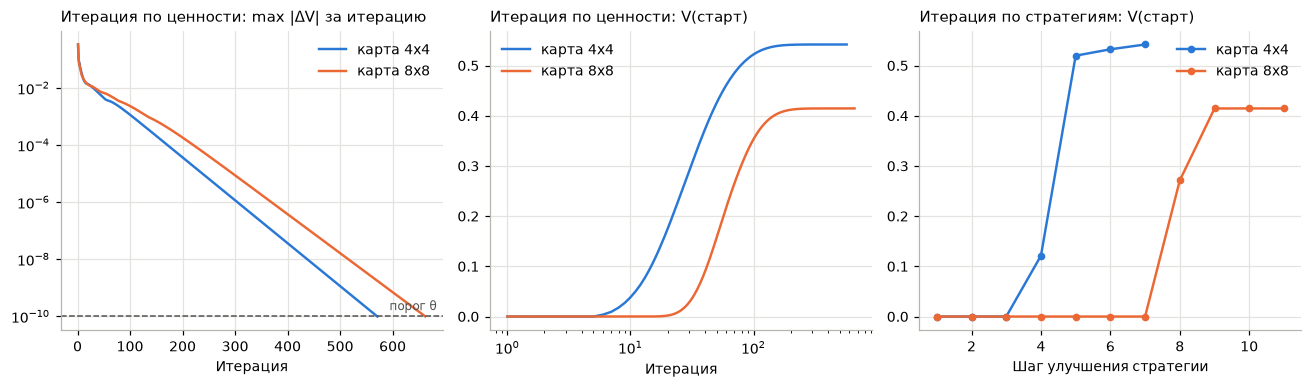

Карта 4x4, итерация по стратегиям по шагам (проходов оценки, изменено действий, V(старт)):
  шаг 1:     1 проходов,   1 действий изменено, V(старт) = 0.0000
  шаг 2:    42 проходов,   6 действий изменено, V(старт) = 0.0000
  шаг 3:   209 проходов,   4 действий изменено, V(старт) = 0.0000
  шаг 4:   207 проходов,   4 действий изменено, V(старт) = 0.1213
  шаг 5:   439 проходов,   1 действий изменено, V(старт) = 0.5198
  шаг 6:   393 проходов,   1 действий изменено, V(старт) = 0.5325
  шаг 7:   471 проходов,   0 действий изменено, V(старт) = 0.5420
Карта 8x8, итерация по стратегиям по шагам (проходов оценки, изменено действий, V(старт)):
  шаг 1:    45 проходов,  13 действий изменено, V(старт) = 0.0000
  шаг 2:   768 проходов,  10 действий изменено, V(старт) = 0.0000
  шаг 3:    51 проходов,  11 действий изменено, V(старт) = 0.0000
  шаг 4:    83 проходов,  13 действий изменено, V(старт) = 0.0000
  шаг 5:   494 проходов,   8 действий изменено, V(старт) = 0.0000
  шаг 6:   436 проходов,  

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for i, name in enumerate(envs):
    vi, pi = solutions[name]
    axes[0].plot(np.arange(1, vi['iterations'] + 1), vi['deltas'], color=SERIES[i], label=f'карта {name}')
    axes[1].plot(np.arange(1, vi['iterations'] + 1), vi['v_start'], color=SERIES[i], label=f'карта {name}')
    axes[2].plot(np.arange(1, pi['improvements'] + 1), pi['history'][:, 2], color=SERIES[i], marker='o',
                 markersize=4, label=f'карта {name}')
axes[0].axhline(THETA, color='#52514e', linestyle='--', linewidth=1)
axes[0].annotate('порог θ', (axes[0].get_xlim()[1], THETA), xytext=(-4, 4), textcoords='offset points',
                 ha='right', fontsize=8, color='#52514e')
axes[0].set_yscale('log')
axes[0].set_title('Итерация по ценности: max |ΔV| за итерацию', loc='left', fontsize=9.5)
axes[0].set_xlabel('Итерация')
axes[1].set_title('Итерация по ценности: V(старт)', loc='left', fontsize=9.5)
axes[1].set_xlabel('Итерация')
axes[1].set_xscale('log')
axes[2].set_title('Итерация по стратегиям: V(старт)', loc='left', fontsize=9.5)
axes[2].set_xlabel('Шаг улучшения стратегии')
for ax in axes:
    ax.legend(loc='best')
plt.tight_layout()
plt.show()

for name in envs:
    _, pi = solutions[name]
    print(f'Карта {name}, итерация по стратегиям по шагам (проходов оценки, изменено действий, V(старт)):')
    for k, (sweeps, changed, v0) in enumerate(pi['history'], 1):
        print(f'  шаг {k}: {int(sweeps):5d} проходов, {int(changed):3d} действий изменено, '
              f'V(старт) = {v0:.4f}')

**Наблюдения.**

* У итерации по ценности ошибка убывает **геометрически**: в логарифмическом масштабе это прямая линия. За каждую
  итерацию изменение уменьшается примерно в одно и то же число раз (в худшем случае в γ раз), поэтому число итераций
  растёт как log(1/θ) / log(1/γ).
* Первые ~5 итераций на 4×4 и ~15 на 8×8 ценность старта равна нулю. Награда есть только у цели, и за одну итерацию
  информация о ней продвигается на одну клетку назад. Пока она не «дошла» до старта, старт выглядит бесполезным.
* У итерации по стратегиям ценность старта тоже сначала ноль: начальная стратегия «везде влево» никогда не доходит до цели.
  Потом за 1–2 шага она подскакивает почти до оптимума. Последние шаги меняют 1 действие или ни одного: это доводка.
* Итерация по стратегиям делает мало шагов улучшения (7 и 11), но каждый шаг дорогой: оценка стратегии занимает
  сотни проходов.

### Проверка стратегий в среде

Запускаем стратегии в самой среде по 10 000 эпизодов и сравниваем со случайной стратегией (как в учебном блокноте,
на каждый эпизод новая случайная стратегия). Рядом приведена точная вероятность дойти до цели без лимита шагов;
для случайной стратегии — среднее по 1000 случайным стратегиям.

Карта  Стратегия                 успех в симуляции   шагов   точная вероятность
4x4    Случайная                            0.0158     9.9               0.0157
4x4    Итерация по ценности                 0.7476    44.2               0.8235
4x4    Итерация по стратегиям               0.7476    44.2               0.8235
8x8    Случайная                            0.0026    40.4               0.0021
8x8    Итерация по ценности                 0.8649    84.7               0.8938
8x8    Итерация по стратегиям               0.8649    84.7               0.8938


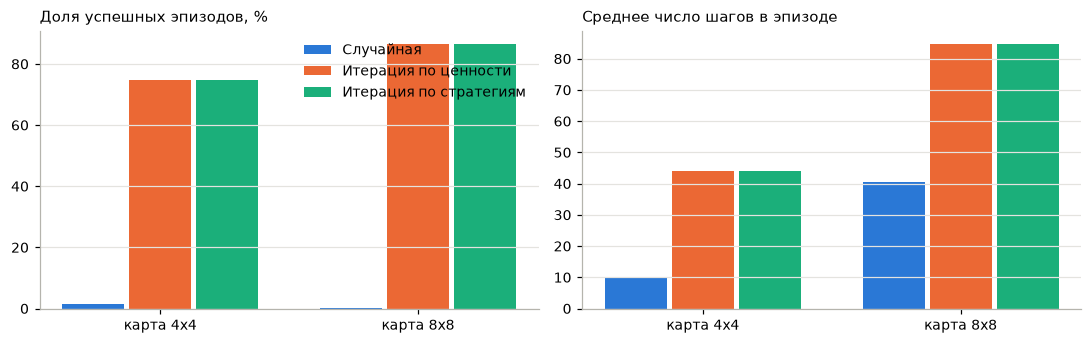

In [11]:
def test_random(env, n_episode=10000, seed=0):
    # Как test_policy, но на каждый эпизод своя случайная стратегия (как в учебном блокноте)
    rng = np.random.default_rng(seed)
    env.reset(seed=seed)
    n_s = env.observation_space.n
    results = np.array([run_episode(env, rng.integers(0, 4, n_s)) for _ in range(n_episode)])
    exact = np.mean([success_probability(env, rng.integers(0, 4, n_s)) for _ in range(1000)])
    return results[:, 0].mean(), results[:, 1].mean(), exact


rows = []
for name, e in envs.items():
    vi, pi = solutions[name]
    rows.append((name, 'Случайная', *test_random(e)))
    for label, policy in [('Итерация по ценности', vi['policy']), ('Итерация по стратегиям', pi['policy'])]:
        success, steps = test_policy(e, policy)
        rows.append((name, label, success, steps, success_probability(e, policy)))

print(f"{'Карта':6s} {'Стратегия':24s} {'успех в симуляции':>18s} {'шагов':>7s} {'точная вероятность':>20s}")
for name, label, success, steps, exact in rows:
    print(f'{name:6s} {label:24s} {success:18.4f} {steps:7.1f} {exact:20.4f}')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
labels = ['Случайная', 'Итерация по ценности', 'Итерация по стратегиям']
x = np.arange(len(envs))
for k, label in enumerate(labels):
    vals = [r for r in rows if r[1] == label]
    axes[0].bar(x + (k - 1) * 0.26, [100 * r[2] for r in vals], width=0.24, color=SERIES[k], label=label)
    axes[1].bar(x + (k - 1) * 0.26, [r[3] for r in vals], width=0.24, color=SERIES[k], label=label)
for ax, title in zip(axes, ['Доля успешных эпизодов, %', 'Среднее число шагов в эпизоде']):
    ax.set_xticks(x, [f'карта {n}' for n in envs])
    ax.set_title(title, loc='left', fontsize=9.5)
    ax.grid(axis='x', visible=False)
axes[0].legend(loc='upper right')
plt.tight_layout()
plt.show()

**Наблюдения.**

* Случайная стратегия доходит до цели в 1.6 % эпизодов на 4×4 (как в учебном блокноте) и в 0.26 % на 8×8.
  Оптимальная — в 74.8 % и 86.5 %. Точный расчёт по модели и симуляция для случайной стратегии совпадают
  (1.57 % и 1.58 %), значит, расчёт верный.
* Для оптимальной стратегии симуляция даёт меньше, чем точный расчёт (74.8 % против 82.4 % на 4×4). Причина — лимит шагов.
  Оптимальная стратегия осторожная и долгая: в среднем 44 шага на 4×4 и 85 на 8×8. Часть эпизодов обрывается
  на 100-м (200-м) шаге, хотя агент ещё не упал и мог бы дойти.
* На карте 8×8 у оптимальной стратегии успех выше, чем на 4×4. Карта больше, но на 4×4 полыньи стоят теснее, и в
  некоторых клетках не получается повернуться к полынье «спиной».

## 6. Влияние коэффициента дисконтирования γ

γ — насколько агент ценит будущие награды: награда через k шагов умножается на γ<sup>k</sup>.
При малом γ далёкая цель «почти ничего не стоит», при γ = 1 неважно, через сколько шагов дойти — важно только дойти.

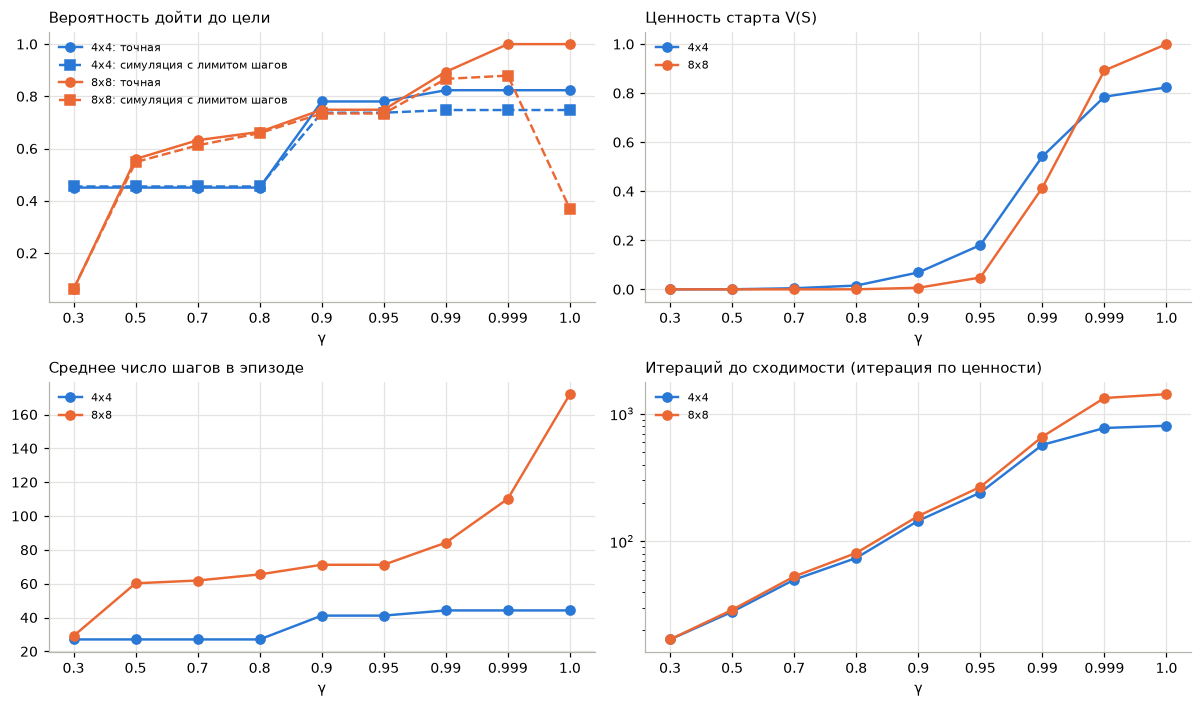

карта      γ  итераций  V(старт)  точная P  симуляция   шагов
4x4      0.3        17    0.0000     0.451      0.455    27.1
4x4      0.5        28    0.0004     0.451      0.455    27.1
4x4      0.7        50    0.0045     0.451      0.455    27.1
4x4      0.8        74    0.0154     0.451      0.455    27.1
4x4      0.9       145    0.0689     0.780      0.737    41.2
4x4     0.95       241    0.1805     0.780      0.737    41.2
4x4     0.99       571    0.5420     0.824      0.748    44.2
4x4    0.999       774    0.7855     0.824      0.748    44.2
4x4        1       806    0.8235     0.824      0.748    44.2
8x8      0.3        17    0.0000     0.061      0.063    29.1
8x8      0.5        29    0.0000     0.560      0.548    60.3
8x8      0.7        53    0.0000     0.632      0.612    61.9
8x8      0.8        81    0.0002     0.664      0.659    65.5
8x8      0.9       158    0.0064     0.749      0.734    71.2
8x8     0.95       267    0.0483     0.749      0.734    71.2
8x8     

In [12]:
gammas = [0.3, 0.5, 0.7, 0.8, 0.9, 0.95, 0.99, 0.999, 1.0]
gamma_rows = {}  # gamma_rows[карта] = список строк по каждому γ
for name, e in envs.items():
    T, R = get_model(e)
    gamma_rows[name] = []
    for g in gammas:
        vi = value_iteration(T, R, g, THETA)
        success, steps = test_policy(e, vi['policy'], n_episode=3000)
        gamma_rows[name].append(dict(gamma=g, iterations=vi['iterations'], v_start=vi['V'][0],
                                     exact=success_probability(e, vi['policy']), success=success, steps=steps,
                                     policy=vi['policy'], V=vi['V']))

fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for i, name in enumerate(envs):
    rows_ = gamma_rows[name]
    g = [r['gamma'] for r in rows_]
    pos = np.arange(len(g))  # γ откладываем равномерно, иначе 0.99, 0.999 и 1.0 сольются
    axes[0, 0].plot(pos, [r['exact'] for r in rows_], marker='o', color=SERIES[i], label=f'{name}: точная')
    axes[0, 0].plot(pos, [r['success'] for r in rows_], marker='s', linestyle='--', color=SERIES[i],
                    label=f'{name}: симуляция с лимитом шагов')
    axes[0, 1].plot(pos, [r['v_start'] for r in rows_], marker='o', color=SERIES[i], label=name)
    axes[1, 0].plot(pos, [r['steps'] for r in rows_], marker='o', color=SERIES[i], label=name)
    axes[1, 1].plot(pos, [r['iterations'] for r in rows_], marker='o', color=SERIES[i], label=name)
titles = ['Вероятность дойти до цели', 'Ценность старта V(S)', 'Среднее число шагов в эпизоде',
          'Итераций до сходимости (итерация по ценности)']
for ax, title in zip(axes.flat, titles):
    ax.set_xticks(np.arange(len(gammas)), [str(g) for g in gammas])
    ax.set_xlabel('γ')
    ax.set_title(title, loc='left', fontsize=9.5)
    ax.legend(loc='best', fontsize=7.5)
axes[1, 1].set_yscale('log')
plt.tight_layout()
plt.show()

print(f"{'карта':5s} {'γ':>6s} {'итераций':>9s} {'V(старт)':>9s} {'точная P':>9s} "
      f"{'симуляция':>10s} {'шагов':>7s}")
for name in envs:
    for r in gamma_rows[name]:
        print(f"{name:5s} {r['gamma']:6g} {r['iterations']:9d} {r['v_start']:9.4f} {r['exact']:9.3f} "
              f"{r['success']:10.3f} {r['steps']:7.1f}")

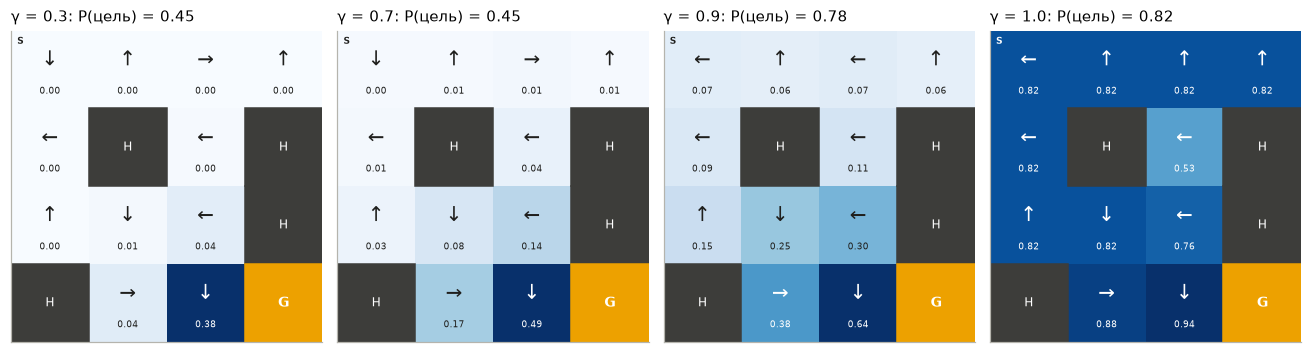

In [13]:
# Как меняется сама стратегия на карте 4x4 при разных γ
show = [0.3, 0.7, 0.9, 1.0]
fig, axes = plt.subplots(1, len(show), figsize=(12, 3.4))
for ax, g in zip(axes, show):
    r = next(r for r in gamma_rows['4x4'] if r['gamma'] == g)
    draw_policy(ax, envs['4x4'], r['V'], r['policy'], f"γ = {g}: P(цель) = {r['exact']:.2f}")
plt.tight_layout()
plt.show()

### Ловушка γ = 1: агенту некуда спешить

На нескользком льду (среда детерминирована) сравним γ = 0.99 и γ = 1.

γ = 0.99: V(старт) = 0.9510, P(цель) = 1.000, в симуляции успех 1.00 за 6 шагов
γ = 1.0: V(старт) = 1.0000, P(цель) = 0.000, в симуляции успех 0.00 за 100 шагов


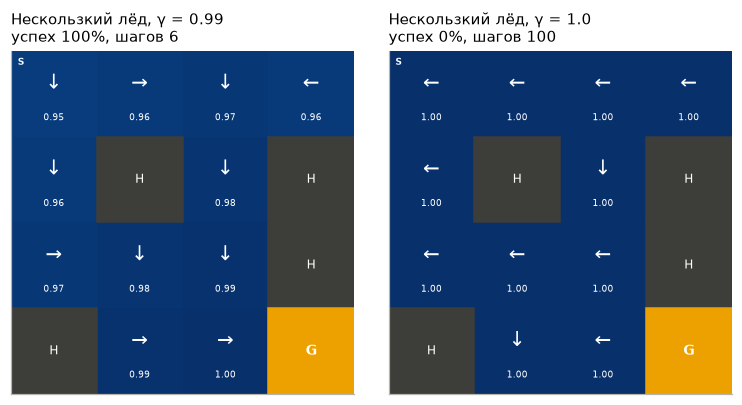

In [14]:
det = make_env('4x4', slippery=False)
T_d, R_d = get_model(det)
fig, axes = plt.subplots(1, 2, figsize=(7, 3.6))
for ax, g in zip(axes, [0.99, 1.0]):
    vi = value_iteration(T_d, R_d, g, THETA)
    success, steps = test_policy(det, vi['policy'], n_episode=100)
    title = f'Нескользкий лёд, γ = {g}\nуспех {success:.0%}, шагов {steps:.0f}'
    draw_policy(ax, det, vi['V'], vi['policy'], title)
    print(f"γ = {g}: V(старт) = {vi['V'][0]:.4f}, P(цель) = {success_probability(det, vi['policy']):.3f}, "
          f"в симуляции успех {success:.2f} за {steps:.0f} шагов")
plt.tight_layout()
plt.show()

**Наблюдения.**

* **Малое γ — агент «близорукий».** При γ = 0.3 ценность цели, до которой 14 шагов, — это 0.3¹⁴ ≈ 5·10⁻⁸. Для агента это
  почти ноль, и он выбирает почти что угодно: на 8×8 успех всего 6 %. С ростом γ стратегия становится дальновиднее,
  и вероятность дойти до цели растёт: на 4×4 с 45 % до 82 %, на 8×8 с 6 % до 100 %.
* **Между скоростью и надёжностью.** При γ < 1 награда через k шагов умножается на γᵏ, поэтому агенту выгодно дойти
  побыстрее, даже рискуя. Чем ближе γ к 1, тем меньше штраф за долгий путь и тем осторожнее стратегия.
  Это видно по числу шагов: на 8×8 оно растёт с 60 (γ = 0.5) до 172 (γ = 1).
* **γ = 1 на 8×8: дойти можно всегда, но очень долго.** Точная вероятность успеха равна 1, но в среднем на это нужно
  больше 170 шагов. В симуляции с лимитом 200 шагов успех падает до 37 %. Лучше всего здесь γ = 0.99–0.999:
  успех 87–88 % в пределах лимита.
* **Ценность старта V(S)** растёт с γ и при γ = 1 становится в точности вероятностью дойти до цели (0.82 и 1.0).
* **Число итераций** растёт с γ: на 4×4 17 итераций при γ = 0.3, 145 при 0.9, 571 при 0.99, 806 при 1.
  При γ < 1 сходимость гарантирована: оператор Беллмана — сжатие с коэффициентом γ, и в худшем случае нужно
  log(1/θ) / log(1/γ) итераций. На практике выходит быстрее: эпизоды обрываются в полыньях и в цели, и это тоже
  «гасит» изменения ценностей. Поэтому сходимость есть даже при γ = 1, хотя и самая медленная.
* **Ловушка γ = 1 на нескользком льду.** Все ценности равны 1: из любой клетки до цели можно дойти наверняка. Ценность
  «дойти за 6 шагов» и «дойти когда-нибудь» одинакова, поэтому все действия равноценны. Жадная стратегия берёт первое,
  «влево», и агент вечно стоит у стены: 0 % успеха. При γ = 0.99 короткий путь ценнее длинного (0.99⁶ > 0.99¹⁰),
  и агент идёт кратчайшим путём за 6 шагов. Вывод: γ < 1 нужен не только для сходимости, но и чтобы агент торопился.

## 7. Влияние порога остановки θ

θ — когда считать, что ценности перестали меняться. Чем больше θ, тем раньше остановка и тем грубее ценности.
Смотрим число итераций, ошибку ценностей по сравнению с очень точным решением и качество полученной стратегии
(карта 8×8, γ = 0.99).

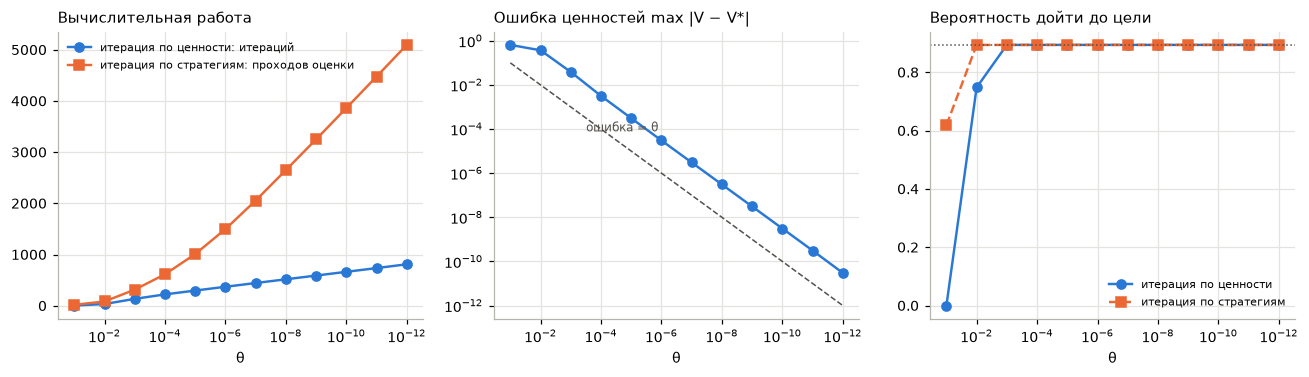

       θ  VI итераций   ошибка V  P(цель) VI  PI улучшений  PI проходов  P(цель) PI
   1e-01            3    6.5e-01      0.0000            12           17      0.6182
   1e-02           33    3.7e-01      0.7479            12           83      0.8937
   1e-03          134    3.9e-02      0.8938            11          314      0.8938
   1e-04          221    3.2e-03      0.8938            11          614      0.8938
   1e-05          296    3.1e-04      0.8938            11         1009      0.8938
   1e-06          370    3.0e-05      0.8938            11         1497      0.8938
   1e-07          443    3.1e-06      0.8938            11         2055      0.8938
   1e-08          516    3.1e-07      0.8938            11         2650      0.8938
   1e-09          589    3.1e-08      0.8938            11         3250      0.8938
   1e-10          662    3.1e-09      0.8938            11         3861      0.8938
   1e-11          735    3.1e-10      0.8938            11         4476     

In [15]:
T8, R8 = get_model(envs['8x8'])
exact_vi = value_iteration(T8, R8, GAMMA, theta=1e-14)  # «эталон» - очень точное решение
thetas = [10.0 ** -k for k in range(1, 13)]
theta_rows = []
for th in thetas:
    vi = value_iteration(T8, R8, GAMMA, th)
    pi = policy_iteration(T8, R8, GAMMA, th)
    theta_rows.append(dict(theta=th, vi_iter=vi['iterations'],
                           pi_impr=pi['improvements'], pi_sweeps=pi['sweeps'],
                           vi_err=np.abs(vi['V'] - exact_vi['V']).max(),
                           vi_exact=success_probability(envs['8x8'], vi['policy']),
                           pi_exact=success_probability(envs['8x8'], pi['policy'])))
best = success_probability(envs['8x8'], exact_vi['policy'])

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
th = [r['theta'] for r in theta_rows]
axes[0].plot(th, [r['vi_iter'] for r in theta_rows], marker='o', color=SERIES[0],
             label='итерация по ценности: итераций')
axes[0].plot(th, [r['pi_sweeps'] for r in theta_rows], marker='s', color=SERIES[1],
             label='итерация по стратегиям: проходов оценки')
axes[1].plot(th, [r['vi_err'] for r in theta_rows], marker='o', color=SERIES[0])
axes[1].plot(th, th, color='#52514e', linestyle='--', linewidth=1)
axes[1].annotate('ошибка = θ', (th[2], th[2]), xytext=(10, -16), textcoords='offset points', fontsize=8,
                 color='#52514e')
axes[2].plot(th, [r['vi_exact'] for r in theta_rows], marker='o', color=SERIES[0],
             label='итерация по ценности')
axes[2].plot(th, [r['pi_exact'] for r in theta_rows], marker='s', color=SERIES[1], linestyle='--',
             label='итерация по стратегиям')
axes[2].axhline(best, color='#52514e', linestyle=':', linewidth=1)
titles = ['Вычислительная работа', 'Ошибка ценностей max |V − V*|', 'Вероятность дойти до цели']
for ax, title in zip(axes, titles):
    ax.set_xscale('log')
    ax.invert_xaxis()  # слева грубый порог, справа точный
    ax.set_xlabel('θ')
    ax.set_title(title, loc='left', fontsize=9.5)
axes[1].set_yscale('log')
axes[0].legend(loc='upper left', fontsize=7.5)
axes[2].legend(loc='lower right', fontsize=7.5)
plt.tight_layout()
plt.show()

print(f"{'θ':>8s} {'VI итераций':>12s} {'ошибка V':>10s} {'P(цель) VI':>11s} {'PI улучшений':>13s} "
      f"{'PI проходов':>12s} {'P(цель) PI':>11s}")
for r in theta_rows:
    print(f"{r['theta']:8.0e} {r['vi_iter']:12d} {r['vi_err']:10.1e} {r['vi_exact']:11.4f} "
          f"{r['pi_impr']:13d} {r['pi_sweeps']:12d} {r['pi_exact']:11.4f}")
print(f'Оптимум: P(цель) = {best:.4f}')

**Наблюдения.**

* Число итераций итерации по ценности растёт **линейно по log(1/θ)**: примерно +73 итерации на каждый порядок θ.
  Это следствие геометрической сходимости.
* Ошибка ценностей остаётся примерно в 30 раз больше θ. Это укладывается в теоретическую оценку
  ‖V − V*‖ ≤ γθ / (1 − γ) = 99θ. То есть малое изменение за итерацию ещё не значит, что ценности точные.
* **Стратегия сходится намного раньше ценностей.** Уже при θ = 10⁻³ (134 итерации из 662) стратегия оптимальна,
  хотя ценности ещё ошибаются на 0.04. При θ = 10⁻¹ (3 итерации) стратегия бесполезна: успех 0.
* Итерация по стратегиям оптимальна уже при θ = 10⁻², а число шагов улучшения от θ почти не зависит (11–12).
  Зато общее число проходов оценки растёт быстрее, чем у итерации по ценности: каждую стратегию приходится оценивать
  с точностью θ.

## 8. Сколько проходов оценки нужно итерации по стратегиям

Классическая итерация по стратегиям оценивает каждую стратегию до сходимости. Модифицированная делает только
k проходов оценки и сразу улучшает стратегию. При k = 1 это почти итерация по ценности. Карта 8×8, γ = 0.99.

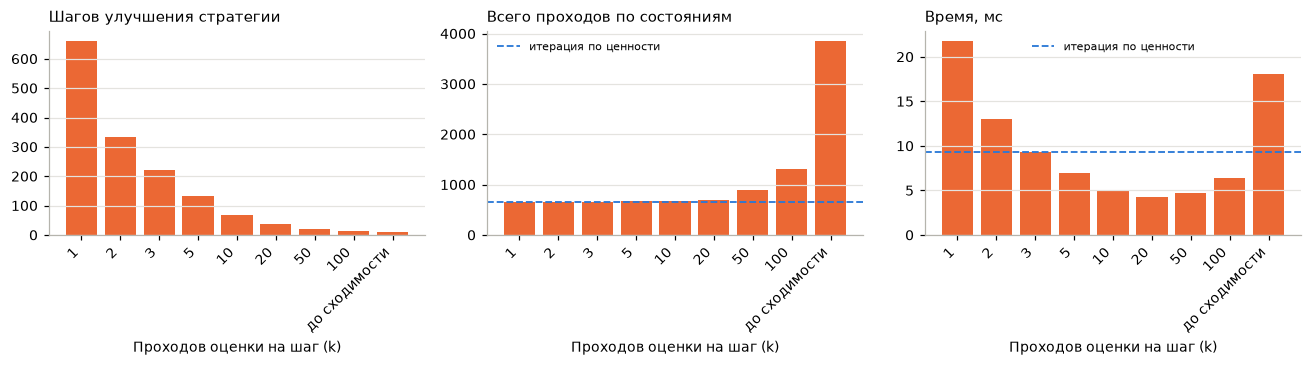

             k  улучшений  проходов  время, мс  P(цель)
             1        662       662       21.8   0.8938
             2        332       663       13.1   0.8938
             3        222       664        9.3   0.8938
             5        134       666        7.0   0.8938
            10         68       674        5.1   0.8938
            20         36       701        4.3   0.8938
            50         19       903        4.7   0.8938
           100         14      1302        6.4   0.8938
 до сходимости         11      3861       18.1   0.8938
            VI                  662        9.3   0.8938


In [16]:
eval_options = [1, 2, 3, 5, 10, 20, 50, 100, None]
mpi_rows = []
for k in eval_options:
    times = []
    for _ in range(3):  # время меряем трижды и берём лучшее, чтобы меньше влиял случайный шум
        t0 = time.perf_counter()
        res = policy_iteration(T8, R8, GAMMA, THETA, eval_sweeps=k)
        times.append(time.perf_counter() - t0)
    mpi_rows.append(dict(k='до сходимости' if k is None else str(k), improvements=res['improvements'],
                         sweeps=res['sweeps'], time=min(times),
                         exact=success_probability(envs['8x8'], res['policy'])))
times = []
for _ in range(3):
    t0 = time.perf_counter()
    vi8 = value_iteration(T8, R8, GAMMA, THETA)
    times.append(time.perf_counter() - t0)
vi_time = min(times)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
labels = [r['k'] for r in mpi_rows]
x = np.arange(len(labels))
axes[0].bar(x, [r['improvements'] for r in mpi_rows], color=SERIES[1])
axes[1].bar(x, [r['sweeps'] for r in mpi_rows], color=SERIES[1])
axes[1].axhline(vi8['iterations'], color=SERIES[0], linestyle='--', linewidth=1.2,
                label='итерация по ценности')
axes[2].bar(x, [1000 * r['time'] for r in mpi_rows], color=SERIES[1])
axes[2].axhline(1000 * vi_time, color=SERIES[0], linestyle='--', linewidth=1.2, label='итерация по ценности')
axes[1].legend(loc='upper left', fontsize=7.5)
axes[2].legend(loc='upper center', fontsize=7.5)
titles = ['Шагов улучшения стратегии', 'Всего проходов по состояниям', 'Время, мс']
for ax, title in zip(axes, titles):
    ax.set_xticks(x, labels, rotation=45, ha='right')
    ax.set_xlabel('Проходов оценки на шаг (k)')
    ax.set_title(title, loc='left', fontsize=9.5)
    ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

print(f"{'k':>14s} {'улучшений':>10s} {'проходов':>9s} {'время, мс':>10s} {'P(цель)':>8s}")
for r in mpi_rows:
    print(f"{r['k']:>14s} {r['improvements']:10d} {r['sweeps']:9d} {1000 * r['time']:10.1f} "
          f"{r['exact']:8.4f}")
print(f"{'VI':>14s} {'':10s} {vi8['iterations']:9d} {1000 * vi_time:10.1f} "
      f"{success_probability(envs['8x8'], vi8['policy']):8.4f}")

**Наблюдения.**

* При k = 1 получается ровно итерация по ценности: 662 шага улучшения = 662 итерации.
* Чем больше k, тем меньше шагов улучшения (662 → 11), но тем больше проходов оценки на каждый шаг.
  До k ≈ 20 общее число проходов почти не растёт (662–701), дальше растёт резко: классический вариант делает 3861 проход.
  Оценивать промежуточные стратегии до полной точности бессмысленно — следующая стратегия всё равно будет другой.
* По времени лучше всего k = 10–20: около 5 мс против 9 мс у итерации по ценности и 18 мс у классической итерации
  по стратегиям. Проход оценки дешевле итерации по ценности (нет перебора действий и максимума),
  а улучшение стратегии делается редко.
* Все варианты нашли одну и ту же оптимальную стратегию (P = 0.894). Модифицированная итерация по стратегиям — это
  общая схема, частные случаи которой — оба классических алгоритма.

## 9. Влияние размера карты

Случайные карты размером n×n (доля льда 0.8; генератор гарантирует, что путь от S до G существует).
Сравниваем вычислительную работу и время двух алгоритмов, γ = 0.99.

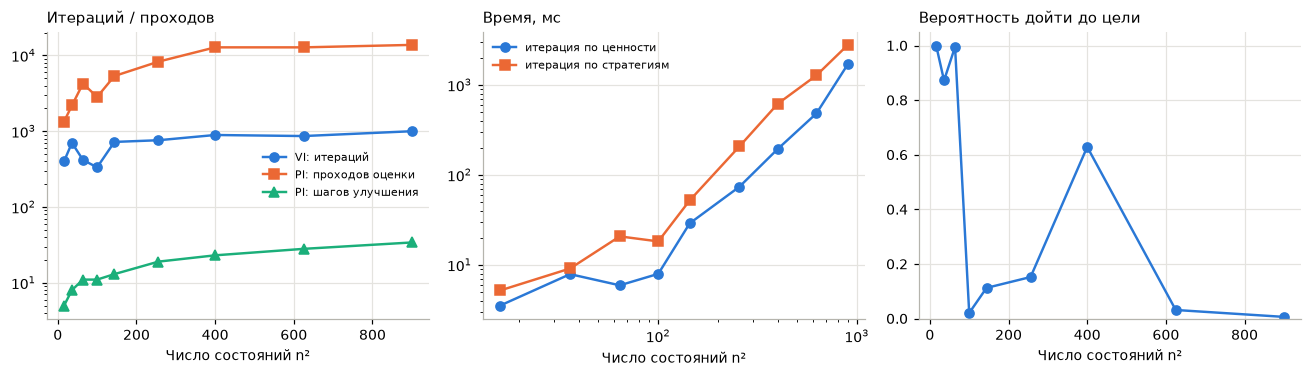

  n  состояний  VI итер.    VI мс  PI улучш.  PI проходов    PI мс  P(цель)  V совпали
  4         16       401      3.5          5         1341      5.2    1.000       True
  6         36       702      7.9          8         2184      9.1    0.872       True
  8         64       417      5.9         11         4242     20.7    0.995       True
 10        100       333      7.9         11         2828     18.2    0.021       True
 12        144       721     28.9         13         5342     52.0    0.112       True
 16        256       759     73.7         19         8266    206.8    0.152       True
 20        400       890    194.5         23        12758    618.3    0.629       True
 25        625       862    480.9         28        12754   1274.6    0.032       True
 30        900       998   1697.4         34        13744   2779.6    0.006       True


In [17]:
sizes = [4, 6, 8, 10, 12, 16, 20, 25, 30]
size_rows = []
for n in sizes:
    desc = generate_random_map(size=n, p=0.8, seed=n)  # seed - чтобы карта была одна и та же при перезапуске
    e = make_env(desc=desc)
    T_n, R_n = get_model(e)
    t0 = time.perf_counter()
    vi = value_iteration(T_n, R_n, GAMMA, THETA)
    t_vi = time.perf_counter() - t0
    t0 = time.perf_counter()
    pi = policy_iteration(T_n, R_n, GAMMA, THETA)
    t_pi = time.perf_counter() - t0
    size_rows.append(dict(n=n, states=n * n, vi_iter=vi['iterations'], vi_time=t_vi,
                          pi_impr=pi['improvements'], pi_sweeps=pi['sweeps'], pi_time=t_pi,
                          exact=success_probability(e, vi['policy']),
                          same=bool(np.allclose(vi['V'], pi['V'], atol=1e-8))))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
states = [r['states'] for r in size_rows]
axes[0].plot(states, [r['vi_iter'] for r in size_rows], marker='o', color=SERIES[0], label='VI: итераций')
axes[0].plot(states, [r['pi_sweeps'] for r in size_rows], marker='s', color=SERIES[1],
             label='PI: проходов оценки')
axes[0].plot(states, [r['pi_impr'] for r in size_rows], marker='^', color=SERIES[2],
             label='PI: шагов улучшения')
axes[1].plot(states, [1000 * r['vi_time'] for r in size_rows], marker='o', color=SERIES[0],
             label='итерация по ценности')
axes[1].plot(states, [1000 * r['pi_time'] for r in size_rows], marker='s', color=SERIES[1],
             label='итерация по стратегиям')
axes[2].plot(states, [r['exact'] for r in size_rows], marker='o', color=SERIES[0])
for ax, title in zip(axes, ['Итераций / проходов', 'Время, мс', 'Вероятность дойти до цели']):
    ax.set_xlabel('Число состояний n²')
    ax.set_title(title, loc='left', fontsize=9.5)
axes[0].set_yscale('log')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[0].legend(loc='center right', fontsize=7.5)
axes[1].legend(loc='upper left', fontsize=7.5)
axes[2].set_ylim(0, 1.05)
plt.tight_layout()
plt.show()

print(f"{'n':>3s} {'состояний':>10s} {'VI итер.':>9s} {'VI мс':>8s} {'PI улучш.':>10s} {'PI проходов':>12s} "
      f"{'PI мс':>8s} {'P(цель)':>8s} {'V совпали':>10s}")
for r in size_rows:
    print(f"{r['n']:3d} {r['states']:10d} {r['vi_iter']:9d} {1000 * r['vi_time']:8.1f} {r['pi_impr']:10d} "
          f"{r['pi_sweeps']:12d} {1000 * r['pi_time']:8.1f} {r['exact']:8.3f} {str(r['same']):>10s}")

**Наблюдения.**

* Число итераций итерации по ценности почти не зависит от размера карты (300–1000). Оно определяется γ и θ,
  а не числом состояний.
* У итерации по стратегиям с ростом карты растёт число шагов улучшения (5 → 34): информация о цели распространяется
  по карте постепенно, а путь длиннее. Число проходов оценки растёт ещё сильнее (1341 → 13744).
* Время растёт примерно как квадрат числа состояний: один проход — умножение матрицы S·A×S на вектор.
  На 900 состояниях итерация по ценности работает около 1.7 с, итерация по стратегиям — около 3 с. Итерация по ценности
  быстрее на всех размерах.
* Вероятность успеха от размера почти не зависит — она определяется расположением полыней на конкретной карте:
  от 1.0 до 0.006. Если полынья перекрывает узкий проход, на скользком льду пройти его почти невозможно.
* Ценности двух алгоритмов совпали на всех картах.

## 10. Влияние скользкости льда

Параметр среды `success_rate` — вероятность пойти туда, куда агент хотел. Остаток делится поровну между двумя
перпендикулярными направлениями. 1/3 — стандартный скользкий лёд, 1 — лёд не скользкий (среда детерминирована).

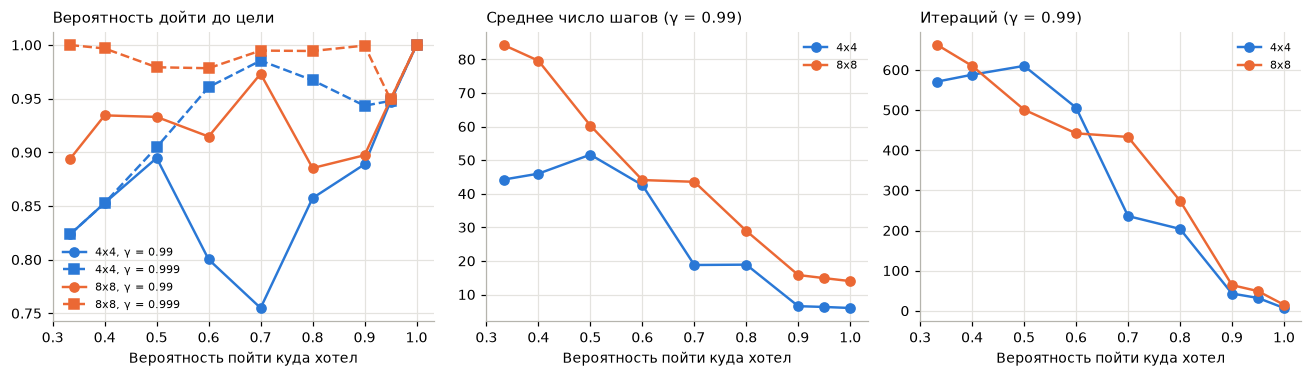

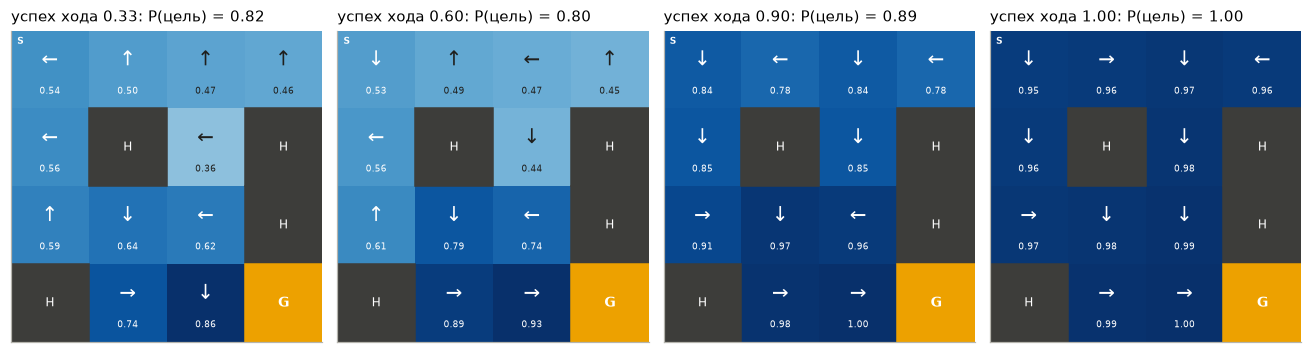

Карта 4x4: успех хода → P(цель) при γ = 0.99 / при γ = 0.999, шагов при γ = 0.99
    0.33 → 0.824 / 0.824, 44 шагов
    0.40 → 0.853 / 0.853, 46 шагов
    0.50 → 0.895 / 0.905, 52 шагов
    0.60 → 0.800 / 0.961, 43 шагов
    0.70 → 0.755 / 0.985, 19 шагов
    0.80 → 0.857 / 0.967, 19 шагов
    0.90 → 0.889 / 0.943, 7 шагов
    0.95 → 0.947 / 0.948, 6 шагов
    1.00 → 1.000 / 1.000, 6 шагов
Карта 8x8: успех хода → P(цель) при γ = 0.99 / при γ = 0.999, шагов при γ = 0.99
    0.33 → 0.894 / 1.000, 84 шагов
    0.40 → 0.934 / 0.997, 80 шагов
    0.50 → 0.933 / 0.979, 60 шагов
    0.60 → 0.915 / 0.978, 44 шагов
    0.70 → 0.973 / 0.995, 44 шагов
    0.80 → 0.885 / 0.994, 29 шагов
    0.90 → 0.897 / 0.999, 16 шагов
    0.95 → 0.949 / 0.949, 15 шагов
    1.00 → 1.000 / 1.000, 14 шагов


In [18]:
rates = [1 / 3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 1.0]
slip_rows = {}
for name in envs:
    slip_rows[name] = []
    for rate in rates:
        e = make_env(name, success_rate=rate)
        T_s, R_s = get_model(e)
        vi = value_iteration(T_s, R_s, GAMMA, THETA)
        vi_far = value_iteration(T_s, R_s, 0.999, THETA)  # агент, который почти не дисконтирует будущее
        success, steps = test_policy(e, vi['policy'], n_episode=3000)
        slip_rows[name].append(dict(rate=rate, exact=success_probability(e, vi['policy']), success=success,
                                    exact_far=success_probability(e, vi_far['policy']),
                                    steps=steps, iterations=vi['iterations'], V=vi['V'],
                                    policy=vi['policy'], env=e))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for i, name in enumerate(envs):
    r_ = slip_rows[name]
    axes[0].plot(rates, [r['exact'] for r in r_], marker='o', color=SERIES[i], label=f'{name}, γ = 0.99')
    axes[0].plot(rates, [r['exact_far'] for r in r_], marker='s', linestyle='--', color=SERIES[i],
                 label=f'{name}, γ = 0.999')
    axes[1].plot(rates, [r['steps'] for r in r_], marker='o', color=SERIES[i], label=name)
    axes[2].plot(rates, [r['iterations'] for r in r_], marker='o', color=SERIES[i], label=name)
titles = ['Вероятность дойти до цели', 'Среднее число шагов (γ = 0.99)', 'Итераций (γ = 0.99)']
for ax, title in zip(axes, titles):
    ax.set_xlabel('Вероятность пойти куда хотел')
    ax.set_title(title, loc='left', fontsize=9.5)
    ax.legend(loc='best', fontsize=7.5)
plt.tight_layout()
plt.show()

# Стратегии на 4x4 при разной скользкости
show = [1 / 3, 0.6, 0.9, 1.0]
fig, axes = plt.subplots(1, len(show), figsize=(12, 3.4))
for ax, rate in zip(axes, show):
    r = next(r for r in slip_rows['4x4'] if r['rate'] == rate)
    draw_policy(ax, r['env'], r['V'], r['policy'], f"успех хода {rate:.2f}: P(цель) = {r['exact']:.2f}")
plt.tight_layout()
plt.show()

for name in envs:
    print(f'Карта {name}: успех хода → P(цель) при γ = 0.99 / при γ = 0.999, шагов при γ = 0.99')
    for r in slip_rows[name]:
        print(f"    {r['rate']:.2f} → {r['exact']:.3f} / {r['exact_far']:.3f}, {r['steps']:.0f} шагов")

**Наблюдения.**

* **Чем менее скользкий лёд, тем короче путь.** Среднее число шагов падает с 44 до 6 на 4×4 и с 84 до 14 на 8×8.
  Число итераций тоже резко падает (с ~600 до ~10): в почти детерминированной среде ценности сходятся быстро.
* **Вероятность успеха растёт не монотонно.** При γ = 0.99 на 4×4: 0.82 при 1/3, 0.90 при 0.5, но 0.76 при 0.7.
  Причина в том, что стратегия максимизирует не вероятность успеха, а дисконтированную награду. Когда ход становится
  надёжнее, быстрый путь мимо полыней становится выгоднее медленного обхода, и агент сознательно рискует.
  При γ = 0.999 скорость почти не ценится, и кривая идёт выше: 0.96–0.99 при 0.6–0.7.
* При вероятности 1/3 агента никогда не сносит назад, поэтому работает приём «упереться в стену». Когда точность хода
  растёт, этот приём перестаёт работать: упираясь в стену, агент почти всегда стоит на месте. Стратегия меняется
  целиком (на картах выше — от «влево, в стену» к прямому пути вниз).
* При вероятности 1 (нескользкий лёд) успех 100 %, путь кратчайший — 6 шагов на 4×4 и 14 на 8×8.

## 11. Влияние плотности полыней

Случайные карты 8×8 с разной долей льда p (остальное — полыньи). Для каждого p — 30 разных карт,
по каждой считается вероятность дойти до цели при оптимальной стратегии.

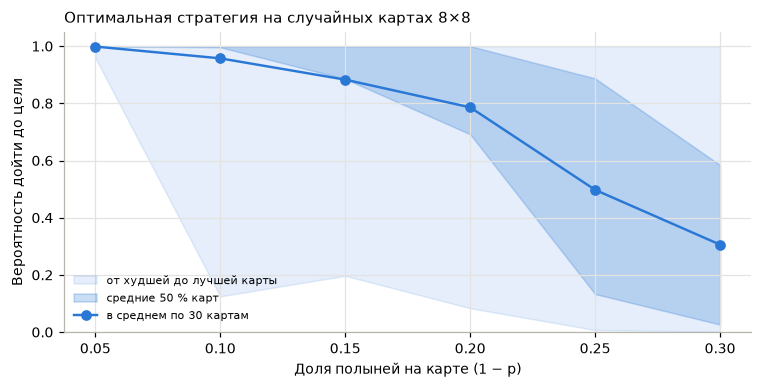

p = 0.95 (≈3.3 полыней): в среднем 0.999, от 0.959 до 1.000
p = 0.90 (≈6.3 полыней): в среднем 0.957, от 0.125 до 1.000
p = 0.85 (≈8.7 полыней): в среднем 0.883, от 0.197 до 1.000
p = 0.80 (≈11.6 полыней): в среднем 0.786, от 0.084 до 1.000
p = 0.75 (≈13.8 полыней): в среднем 0.498, от 0.007 до 1.000
p = 0.70 (≈16.7 полыней): в среднем 0.306, от 0.001 до 1.000


In [19]:
probs = [0.95, 0.9, 0.85, 0.8, 0.75, 0.7]
hole_rows = []
for p in probs:
    values, holes = [], []
    for seed in range(30):
        desc = generate_random_map(size=8, p=p, seed=seed)
        e = make_env(desc=desc)
        T_h, R_h = get_model(e)
        vi = value_iteration(T_h, R_h, GAMMA, THETA)
        values.append(success_probability(e, vi['policy']))
        holes.append(''.join(desc).count('H'))
    hole_rows.append(dict(p=p, mean=np.mean(values), q25=np.percentile(values, 25),
                          q75=np.percentile(values, 75), min=np.min(values), max=np.max(values),
                          holes=np.mean(holes), values=values))

fig, ax = plt.subplots(figsize=(7, 3.6))
x = [1 - r['p'] for r in hole_rows]  # доля полыней
ax.fill_between(x, [r['min'] for r in hole_rows], [r['max'] for r in hole_rows], color=SERIES[0], alpha=0.12,
                label='от худшей до лучшей карты')
ax.fill_between(x, [r['q25'] for r in hole_rows], [r['q75'] for r in hole_rows], color=SERIES[0], alpha=0.25,
                label='средние 50 % карт')
ax.plot(x, [r['mean'] for r in hole_rows], marker='o', color=SERIES[0], label='в среднем по 30 картам')
ax.set_xlabel('Доля полыней на карте (1 − p)')
ax.set_ylabel('Вероятность дойти до цели')
ax.set_ylim(0, 1.05)
ax.set_title('Оптимальная стратегия на случайных картах 8×8', loc='left', fontsize=9.5)
ax.legend(loc='lower left', fontsize=7.5)
plt.tight_layout()
plt.show()

for r in hole_rows:
    print(f"p = {r['p']:.2f} (≈{r['holes']:.1f} полыней): в среднем {r['mean']:.3f}, "
          f"от {r['min']:.3f} до {r['max']:.3f}")

**Наблюдения.**

* Чем больше полыней, тем ниже вероятность дойти даже при оптимальной стратегии: в среднем 99.9 % при 5 % полыней,
  79 % при 20 % и 31 % при 30 %.
* Разброс между картами огромный. При одной и той же доле полыней (20 %) встречаются карты и со 100 %, и с 8 %
  успеха. Важно не столько число полыней, сколько их расположение: две полыньи по бокам узкого прохода хуже десяти
  полыней в стороне от пути.
* Генератор `generate_random_map` гарантирует, что путь до цели существует. Но на скользком льду существования пути
  мало: вдоль пути не должно быть клеток, где полыньи стоят с двух сторон.

## 12. Влияние наград: штраф за шаг и за полынью

Меняем награды среды (`reward_schedule` = награда за цель, за полынью, за шаг по льду) и смотрим, какую стратегию
находит итерация по ценности. Качество проверяем всегда на стандартных наградах: вероятность дойти до цели и число шагов.
Карта 4×4, скользкий лёд, γ = 0.99.

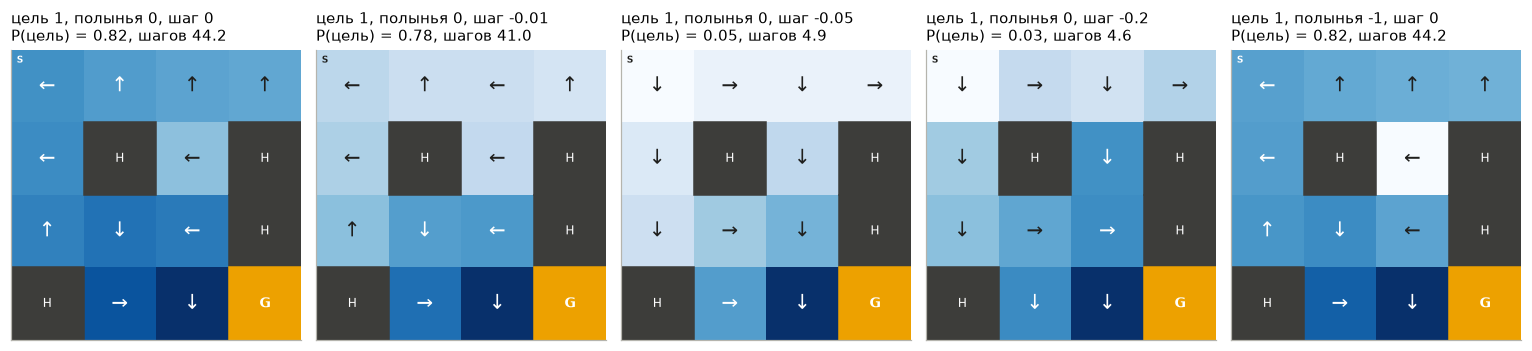

награды (1, 0, 0): P(цель) = 0.824, в симуляции 0.748, шагов 44.2, VI и PI совпали: True
награды (1, 0, -0.01): P(цель) = 0.780, в симуляции 0.736, шагов 41.0, VI и PI совпали: True
награды (1, 0, -0.05): P(цель) = 0.049, в симуляции 0.047, шагов 4.9, VI и PI совпали: True
награды (1, 0, -0.2): P(цель) = 0.033, в симуляции 0.030, шагов 4.6, VI и PI совпали: True
награды (1, -1, 0): P(цель) = 0.824, в симуляции 0.748, шагов 44.2, VI и PI совпали: True


In [20]:
schedules = [(1, 0, 0), (1, 0, -0.01), (1, 0, -0.05), (1, 0, -0.2), (1, -1, 0)]
reward_rows = []
for sch in schedules:
    e = make_env('4x4', reward_schedule=sch)
    T_r, R_r = get_model(e)
    vi = value_iteration(T_r, R_r, GAMMA, THETA)
    pi = policy_iteration(T_r, R_r, GAMMA, THETA)
    clean = make_env('4x4')  # проверяем на стандартной среде: те же переходы, награда 1 только за цель
    success, steps = test_policy(clean, vi['policy'], n_episode=10000)
    reward_rows.append(dict(schedule=sch, V=vi['V'], policy=vi['policy'],
                            exact=success_probability(clean, vi['policy']), success=success, steps=steps,
                            same=bool(np.allclose(vi['V'], pi['V'], atol=1e-8))))

fig, axes = plt.subplots(1, len(schedules), figsize=(14, 3.5))
for ax, r in zip(axes, reward_rows):
    g, h, f = r['schedule']
    # ценности со штрафами бывают отрицательными - для цвета сдвигаем их к нулю
    draw_policy(ax, envs['4x4'], r['V'] - r['V'].min(), r['policy'],
                f"цель {g}, полынья {h}, шаг {f}\nP(цель) = {r['exact']:.2f}, шагов {r['steps']:.1f}",
                values=False)
plt.tight_layout()
plt.show()

for r in reward_rows:
    print(f"награды {r['schedule']}: P(цель) = {r['exact']:.3f}, в симуляции {r['success']:.3f}, "
          f"шагов {r['steps']:.1f}, VI и PI совпали: {r['same']}")

**Наблюдения.**

* **Маленький штраф за шаг (−0.01)** подгоняет агента: путь короче (41 шаг вместо 44), но риск выше
  (78 % вместо 82 %).
* **Большой штраф за шаг (−0.05 и −0.2)** даёт неожиданный результат: агент прыгает в полынью. Осторожный путь до цели
  длится ~44 шага и стоит 44 · 0.05 ≈ 2.2, больше награды за цель. Выгоднее закончить эпизод сразу: успех 3–5 %,
  эпизод длится 5 шагов. Это пример того, как неудачно подобранная награда ломает поведение агента.
* **Штраф −1 за полынью** при γ = 0.99 стратегию не изменил: она и так избегала полыней изо всех сил.
* Вывод: награда задаёт, *что* агент оптимизирует. Алгоритмы честно находят оптимум для заданной награды,
  даже если он не совпадает с тем, чего мы хотели.
* Итерация по ценности и итерация по стратегиям совпали при всех вариантах наград.

## 13. Сводная таблица

In [21]:
print('Оптимальная стратегия (γ = 0.99, θ = 1e-10)')
print(f"{'':28s} {'карта 4x4':>12s} {'карта 8x8':>12s}")
vi4, pi4 = solutions['4x4']
vi8_, pi8 = solutions['8x8']
table = [
    ('VI: итераций', vi4['iterations'], vi8_['iterations']),
    ('PI: шагов улучшения', pi4['improvements'], pi8['improvements']),
    ('PI: проходов оценки', pi4['sweeps'], pi8['sweeps']),
    ('VI: время, мс', round(1000 * vi4['time'], 1), round(1000 * vi8_['time'], 1)),
    ('PI: время, мс', round(1000 * pi4['time'], 1), round(1000 * pi8['time'], 1)),
    ('V(старт)', round(vi4['V'][0], 4), round(vi8_['V'][0], 4)),
]
for label, a, b in table:
    print(f'{label:28s} {a:>12} {b:>12}')
print()
for name, label, success, steps, exact in rows:
    print(f'{name}  {label:24s} успех в симуляции {success:.3f}, шагов {steps:5.1f}, '
          f'точная вероятность {exact:.3f}')

Оптимальная стратегия (γ = 0.99, θ = 1e-10)
                                карта 4x4    карта 8x8
VI: итераций                          571          662
PI: шагов улучшения                     7           11
PI: проходов оценки                  1762         3861
VI: время, мс                        10.4          9.5
PI: время, мс                        15.1         18.3
V(старт)                            0.542       0.4146

4x4  Случайная                успех в симуляции 0.016, шагов   9.9, точная вероятность 0.016
4x4  Итерация по ценности     успех в симуляции 0.748, шагов  44.2, точная вероятность 0.824
4x4  Итерация по стратегиям   успех в симуляции 0.748, шагов  44.2, точная вероятность 0.824
8x8  Случайная                успех в симуляции 0.003, шагов  40.4, точная вероятность 0.002
8x8  Итерация по ценности     успех в симуляции 0.865, шагов  84.7, точная вероятность 0.894
8x8  Итерация по стратегиям   успех в симуляции 0.865, шагов  84.7, точная вероятность 0.894


## 14. Выводы

1. **Оба алгоритма находят одну и ту же оптимальную стратегию** при любых параметрах: ценности совпадают с точностью
   до 10⁻⁸ и лучше. Оптимальная стратегия на 4×4 доходит до цели с вероятностью 0.82, на 8×8 — 0.89 (γ = 0.99).
   Случайная — 1.6 % и 0.2 %.
2. **Итерация по ценности** делает много дешёвых итераций (сотни), **итерация по стратегиям** — мало дорогих шагов
   (5–34), каждый с сотнями проходов оценки. В этой задаче итерация по ценности быстрее во всех опытах.
   Быстрее всех — **модифицированная** итерация по стратегиям с 10–20 проходами оценки на шаг: примерно вдвое быстрее
   итерации по ценности.
3. **γ сильнее всего влияет на результат.** Малое γ делает агента близоруким (успех 6 % на 8×8 при γ = 0.3).
   Большое γ делает его осторожным и медленным, а число итераций растёт (571 при γ = 0.99 против 17 при γ = 0.3). При γ = 1 возможна ловушка:
   все пути к цели равноценны, и жадная стратегия может стоять на месте вечно. Лучшие значения в опытах — 0.99–0.999.
4. **θ влияет на точность ценностей, но стратегия становится оптимальной намного раньше.** Число итераций растёт как
   log(1/θ), а ошибка ценностей может быть в 1/(1 − γ) раз больше θ.
5. **Параметры среды:** чем менее скользкий лёд, тем короче путь и быстрее сходимость. Вероятность успеха при этом
   меняется немонотонно: агент меняет надёжность на скорость. Чем больше полыней, тем ниже успех, но решает
   их расположение, а не количество. Размер карты почти не влияет на число итераций, но время растёт как квадрат
   числа состояний.
6. **Награда определяет поведение.** Большой штраф за шаг заставляет агента прыгать в полынью, чтобы быстрее закончить.
   Алгоритмы оптимизируют ровно то, что задано наградой.
7. **Ограничение методов.** Оба алгоритма требуют полной модели среды (`env.P`) и перебирают все состояния на каждом
   проходе. Для больших задач и сред без известной модели нужны методы, которые учатся на опыте: Монте-Карло,
   TD-обучение, Q-learning.